# Multi-Pattern Fraud Detection Baseline

In [6]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [7]:
%pip install -q mlflow xgboost

## Setup

In [8]:
import sys
import time
import warnings
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mlflow
from sklearn.model_selection import train_test_split, ParameterGrid
from sklearn.preprocessing import RobustScaler, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    average_precision_score, roc_auc_score, roc_curve,
    precision_recall_curve, precision_score, recall_score,
    f1_score, confusion_matrix
)
from xgboost import XGBClassifier

warnings.filterwarnings('ignore', category=FutureWarning)

GLOBAL_SEED = 42
np.random.seed(GLOBAL_SEED)
CSV_PATH = "/content/drive/MyDrive/Synthetic Banking Transaction Dataset with Multi-P/Synthetic Banking Transaction Dataset with Multi-P/Fraud Detection Dataset-bmJaU4/Fraud Detection Dataset.csv"
TARGET = 'is_fraud'
SUBTYPE_COL = 'fraud_type'
ID_COLS = ['transaction_id', 'customer_id', 'card_id', 'device_id', 'ip_address', 'merchant_id']
CAT_COLS = ['merchant_category', 'merchant_country', 'transaction_type']
MAX_LEGIT_TREE = 5_000
MLFLOW_TRACKING_URI = 'sqlite:///mlflow.db'
MLFLOW_EXPERIMENT = 'fraud-traditional-training'
XKCD_STYLE = True
LOG_PLOTS_TO_MLFLOW = False
PLOT_DIR = Path('plots')
PLOT_DIR.mkdir(exist_ok=True)

mlflow.set_tracking_uri(MLFLOW_TRACKING_URI)
mlflow.set_experiment(MLFLOW_EXPERIMENT)
mlflow.autolog(disable=True)

print('Python:', sys.version.split()[0])
print('pandas:', pd.__version__)
print('NumPy:', np.__version__)
print('Global seed:', GLOBAL_SEED)
print('CSV path:', CSV_PATH)
print('MLflow tracking URI:', mlflow.get_tracking_uri())
print('Experiment:', MLFLOW_EXPERIMENT)

Python: 3.13.16
pandas: 2.2.3
NumPy: 2.1.3
Global seed: 42
CSV path: /content/drive/MyDrive/Synthetic Banking Transaction Dataset with Multi-P/Synthetic Banking Transaction Dataset with Multi-P/Fraud Detection Dataset-bmJaU4/Fraud Detection Dataset.csv
MLflow tracking URI: sqlite:///mlflow.db
Experiment: fraud-traditional-training


## Load Dataset

In [9]:
df_raw = pd.read_parquet(CSV_PATH) if CSV_PATH.endswith('.parquet') else pd.read_csv(CSV_PATH)

print('Shape:', df_raw.shape)
print(df_raw.dtypes.to_string())
print(df_raw.head(3).T.to_string())

Shape: (1000000, 17)
transaction_id         object
timestamp              object
customer_id            object
card_id                object
device_id              object
ip_address             object
merchant_id            object
merchant_category      object
merchant_country       object
merchant_city          object
merchant_latitude     float64
merchant_longitude    float64
transaction_type       object
amount                float64
currency               object
is_fraud                int64
fraud_type             object
                                            0                          1                          2
transaction_id                TXN000000000001            TXN000000000002            TXN000000000003
timestamp           2025-10-19T07:46:29+00:00  2025-06-29T01:09:39+00:00  2025-07-06T10:28:29+00:00
customer_id                       CUST0018039                CUST0040966                CUST0055324
card_id                         CARD0018039-2              CARD004096

## Inspect Dataset

In [10]:
print('A1 - shape:', df_raw.shape)

print('\nA2 - target values:', sorted(df_raw[TARGET].unique().tolist()))
print(df_raw[TARGET].value_counts().to_string())
print(f'Fraud rate: {df_raw[TARGET].mean() * 100:.3f}%')

print('\nA3 - fraud_type counts (fraud rows only):')
print(df_raw.loc[df_raw[TARGET] == 1, SUBTYPE_COL].value_counts(dropna=False).to_string())
print('fraud_type non-null on legit rows:', df_raw.loc[df_raw[TARGET] == 0, SUBTYPE_COL].notna().sum())

print('\nA4 - missing values:')
print(df_raw.isnull().sum()[df_raw.isnull().sum() > 0].to_string())

print('\nA5 - duplicates: full rows =', df_raw.duplicated().sum(),
      '| transaction_id =', df_raw['transaction_id'].duplicated().sum())

print('\nA6 - cardinality of categorical columns:')
print(df_raw.select_dtypes('object').nunique().to_string())

print('\nA7 - amount stats by class:')
print(df_raw.groupby(TARGET)['amount'].describe().round(2).to_string())

print('\nA8 - timestamp range:', df_raw['timestamp'].min(), '->', df_raw['timestamp'].max())

A1 - shape: (1000000, 17)

A2 - target values: [0, 1]
is_fraud
0    998510
1      1490
Fraud rate: 0.149%

A3 - fraud_type counts (fraud rows only):
fraud_type
card_testing             800
geo_anomaly              400
account_takeover         210
money_laundering_ring     80
fraud_type non-null on legit rows: 0

A4 - missing values:
fraud_type    998510

A5 - duplicates: full rows = 0 | transaction_id = 0

A6 - cardinality of categorical columns:
transaction_id       1000000
timestamp             984478
customer_id            99996
card_id               238624
device_id             196942
ip_address            980372
merchant_id            20080
merchant_category         11
merchant_country          10
merchant_city          13333
transaction_type           2
currency                   1
fraud_type                 4

A7 - amount stats by class:
             count   mean    std  min   25%    50%    75%      max
is_fraud                                                          
0        

## Feature Engineering and Preprocessing

In [11]:
df_clean = df_raw.copy()
subtype = df_clean[SUBTYPE_COL].fillna('legit')

DROP_COLS = ID_COLS + [
    'merchant_city', 'currency', 'timestamp', TARGET, SUBTYPE_COL,
    'merchant_latitude', 'merchant_longitude'
]

X = df_clean.drop(columns=DROP_COLS)
X = pd.get_dummies(X, columns=CAT_COLS, dtype=int)
y = df_clean[TARGET].copy()

d = df_raw.copy()
d['ts'] = pd.to_datetime(d['timestamp'], utc=True)
d = d.sort_values('ts')
cust_n = d.groupby('customer_id')['amount'].transform('size')
d['secs_prev_card'] = np.log1p(d.groupby('card_id')['ts'].diff().dt.total_seconds().fillna(1e7))
d['card_txn_count'] = d.groupby('card_id')['card_id'].transform('size')
d['device_n_cust'] = d.groupby('device_id')['customer_id'].transform('nunique')
d['cust_device_share'] = d.groupby(['customer_id', 'device_id'])['amount'].transform('size') / cust_n
d['amount_vs_cust_mean'] = d['amount'] / d.groupby('customer_id')['amount'].transform('mean')

NEW_FEATS = [
    'secs_prev_card', 'card_txn_count', 'device_n_cust',
    'cust_device_share', 'amount_vs_cust_mean'
]
X[NEW_FEATS] = d[NEW_FEATS].reindex(X.index)
feature_cols = X.columns.tolist()
SCALE_COLS = ['amount', 'card_txn_count', 'device_n_cust', 'amount_vs_cust_mean']

assert X.isnull().sum().sum() == 0
assert X.select_dtypes(exclude=[np.number]).shape[1] == 0

print('X shape:', X.shape)
print('Number of features:', len(feature_cols))
print('Fraud type counts:')
print(subtype[subtype != 'legit'].value_counts().to_string())

X shape: (1000000, 29)
Number of features: 29
Fraud type counts:
fraud_type
card_testing             800
geo_anomaly              400
account_takeover         210
money_laundering_ring     80


## Stratified Data Split and Scaling

In [12]:
idx_all = X.index.to_numpy()

idx_devval, idx_eval = train_test_split(
    idx_all, test_size=0.15, random_state=GLOBAL_SEED, stratify=subtype.loc[idx_all].values)

idx_dev, idx_val = train_test_split(
    idx_devval, test_size=0.30, random_state=GLOBAL_SEED, stratify=subtype.loc[idx_devval].values)

scaler = RobustScaler()
scaler.fit(X.loc[idx_dev, SCALE_COLS])

X_dev, X_val, X_eval = X.loc[idx_dev].copy(), X.loc[idx_val].copy(), X.loc[idx_eval].copy()
for part in (X_dev, X_val, X_eval):
    part[SCALE_COLS] = scaler.transform(part[SCALE_COLS])

y_dev, y_val, y_eval = y.loc[idx_dev], y.loc[idx_val], y.loc[idx_eval]
subtype_dev, subtype_val, subtype_eval = subtype.loc[idx_dev], subtype.loc[idx_val], subtype.loc[idx_eval]

assert len(set(idx_dev) & set(idx_val)) == 0
assert len(set(idx_dev) & set(idx_eval)) == 0
assert len(set(idx_val) & set(idx_eval)) == 0
assert len(idx_dev) + len(idx_val) + len(idx_eval) == len(X)

print('Split sizes:')
for name, yy in [('dev', y_dev), ('val', y_val), ('eval', y_eval)]:
    print(f'  {name:<5}: {len(yy):>8,} rows | fraud={int(yy.sum()):>5,} ({yy.mean() * 100:.3f}%)')

print('\nFraud type counts per split:')
print(pd.DataFrame({'dev': subtype_dev[subtype_dev != 'legit'].value_counts(),
                    'val': subtype_val[subtype_val != 'legit'].value_counts(),
                    'eval': subtype_eval[subtype_eval != 'legit'].value_counts()}).to_string())

Split sizes:
  dev  :  595,000 rows | fraud=  886 (0.149%)
  val  :  255,000 rows | fraud=  380 (0.149%)
  eval :  150,000 rows | fraud=  224 (0.149%)

Fraud type counts per split:
                       dev  val  eval
fraud_type                           
card_testing           476  204   120
geo_anomaly            238  102    60
account_takeover       125   53    32
money_laundering_ring   47   21    12


## Training Data and Evaluation Helpers

In [13]:
Xtr_full = X_dev.values
ytr_full = y_dev.values
Xv, yv = X_val.values, y_val.values

def build_train_set(max_legit):
    fraud_pos = np.where(ytr_full == 1)[0]
    legit_pos = np.where(ytr_full == 0)[0]
    if max_legit is not None and max_legit < len(legit_pos):
        legit_pos = np.random.RandomState(GLOBAL_SEED).choice(legit_pos, size=max_legit, replace=False)
    pos = np.concatenate([fraud_pos, legit_pos])
    np.random.RandomState(GLOBAL_SEED).shuffle(pos)
    return Xtr_full[pos], ytr_full[pos]

TRAIN_SETS = {'tree': build_train_set(MAX_LEGIT_TREE)}
for k, (Xt, yt) in TRAIN_SETS.items():
    print(f'Train set [{k}]: {Xt.shape}  fraud={int(yt.sum())}  legit={int((yt == 0).sum())}')
print(f'Validation     : {Xv.shape}  fraud={int(yv.sum())}  legit={int((yv == 0).sum())}')

def get_scores(model, X):
    if hasattr(model, 'predict_proba'):
        return model.predict_proba(X)[:, 1]
    return model.decision_function(X)

def best_f1_threshold(y_true, scores):
    p, r, thr = precision_recall_curve(y_true, scores)
    f1 = 2 * p[:-1] * r[:-1] / (p[:-1] + r[:-1] + 1e-12)
    return float(thr[np.argmax(f1)])

def score_split(y_true, scores, threshold):
    fpr, tpr, _ = roc_curve(y_true, scores)
    pred = (scores >= threshold).astype(int)
    return {
        'ap': average_precision_score(y_true, scores),
        'auc': roc_auc_score(y_true, scores),
        'recall_at_1pct_fpr': float(tpr[fpr <= 0.01].max()),
        'precision': precision_score(y_true, pred, zero_division=0),
        'recall': recall_score(y_true, pred),
        'f1': f1_score(y_true, pred),
    }

METRIC_KEYS = ['ap', 'auc', 'recall_at_1pct_fpr', 'precision', 'recall', 'f1']
print('Helpers ready.')

Train set [tree]: (5886, 29)  fraud=886  legit=5000
Validation     : (255000, 29)  fraud=380  legit=254620
Helpers ready.


## Models and Parameter Grids

In [14]:
def pos_weight(y):
    return float((y == 0).sum() / max((y == 1).sum(), 1))

MODELS = {
    'random_forest': dict(
        data='tree',
        make=lambda p, y: RandomForestClassifier(
            class_weight='balanced', n_jobs=-1, random_state=GLOBAL_SEED, **p),
        grid=dict(n_estimators=[100, 1500], max_depth=[None, 10], min_samples_leaf=[1, 5]),
    ),
    'xgboost': dict(
        data='tree',
        make=lambda p, y: XGBClassifier(
            tree_method='hist', subsample=0.8, colsample_bytree=0.8,
            scale_pos_weight=pos_weight(y), eval_metric='aucpr',
            n_jobs=-1, random_state=GLOBAL_SEED, **p),
        grid=dict(n_estimators=[100, 1500], max_depth=[3, 6], learning_rate=[0.05, 0.1]),
    ),
    'logistic_regression': dict(
        data='tree',
        make=lambda p, y: Pipeline([
            ('scale', StandardScaler()),
            ('clf', LogisticRegression(class_weight='balanced', solver='liblinear',
                                       max_iter=5000, random_state=GLOBAL_SEED, **p)),
        ]),
        grid=dict(C=[0.001, 0.01, 0.1, 1, 10, 100], penalty=['l1', 'l2']),
    ),
}

print('Grid points per model:', {k: len(ParameterGrid(v['grid'])) for k, v in MODELS.items()},
      '| total runs:', sum(len(ParameterGrid(m['grid'])) for m in MODELS.values()))

Grid points per model: {'random_forest': 8, 'xgboost': 8, 'logistic_regression': 12} | total runs: 28


## Run Grid Search

In [15]:
VAL_SCORES = {}

def run_config(family, spec, params, run_idx):
    Xt, yt = TRAIN_SETS[spec['data']]
    with mlflow.start_run(run_name=f'{family}_{run_idx:02d}'):
        mlflow.set_tags({'model_family': family, 'training': 'traditional supervised'})
        mlflow.log_params({**params, 'n_train': len(yt), 'n_train_fraud': int(yt.sum())})

        t0 = time.time()
        model = spec['make'](params, yt)
        model.fit(Xt, yt)
        fit_s = time.time() - t0
        scores = get_scores(model, Xv)
        VAL_SCORES[(family, run_idx)] = scores
        thr = best_f1_threshold(yv, scores)
        m = score_split(yv, scores, thr)

        mlflow.log_metrics({f'val_{k}': v for k, v in m.items()})
        mlflow.log_metric('val_threshold', thr)
        mlflow.log_metric('fit_time_s', fit_s)
    return m, thr

all_summaries = {}
t_all = time.time()
for family, spec in MODELS.items():
    grid = list(ParameterGrid(spec['grid']))
    print(f'\n=== {family}: {len(grid)} grid points ===')
    for i, params in enumerate(grid):
        t0 = time.time()
        m, thr = run_config(family, spec, params, i)
        all_summaries[(family, i)] = dict(params=params, metrics=m, threshold=thr)
        print(f'  [{i + 1:>2}/{len(grid)}] {params}  val AP={m["ap"]:.3f}  AUC={m["auc"]:.3f}  '
              f'F1={m["f1"]:.3f}  ({time.time() - t0:.0f}s)')

print(f'\nDone in {(time.time() - t_all) / 60:.1f} min.')


=== random_forest: 8 grid points ===
  [ 1/8] {'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 100}  val AP=0.614  AUC=0.876  F1=0.677  (3s)
  [ 2/8] {'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 1500}  val AP=0.628  AUC=0.871  F1=0.681  (38s)
  [ 3/8] {'max_depth': None, 'min_samples_leaf': 5, 'n_estimators': 100}  val AP=0.629  AUC=0.874  F1=0.681  (4s)
  [ 4/8] {'max_depth': None, 'min_samples_leaf': 5, 'n_estimators': 1500}  val AP=0.631  AUC=0.873  F1=0.699  (35s)
  [ 5/8] {'max_depth': 10, 'min_samples_leaf': 1, 'n_estimators': 100}  val AP=0.625  AUC=0.881  F1=0.689  (2s)
  [ 6/8] {'max_depth': 10, 'min_samples_leaf': 1, 'n_estimators': 1500}  val AP=0.627  AUC=0.880  F1=0.696  (25s)
  [ 7/8] {'max_depth': 10, 'min_samples_leaf': 5, 'n_estimators': 100}  val AP=0.634  AUC=0.879  F1=0.693  (2s)
  [ 8/8] {'max_depth': 10, 'min_samples_leaf': 5, 'n_estimators': 1500}  val AP=0.634  AUC=0.877  F1=0.702  (24s)

=== xgboost: 8 grid points ===
  [ 1/8] {'learnin

## Compare Validation Results

Validation results, ranked by average precision:
           family               run                                                            params     ap    auc  recall_at_1pct_fpr  precision  recall     f1
0   random_forest  random_forest_07    {'max_depth': 10, 'min_samples_leaf': 5, 'n_estimators': 1500}  0.634  0.877               0.732      0.875   0.587  0.702
1   random_forest  random_forest_06     {'max_depth': 10, 'min_samples_leaf': 5, 'n_estimators': 100}  0.634  0.879               0.732      0.889   0.568  0.693
2   random_forest  random_forest_03  {'max_depth': None, 'min_samples_leaf': 5, 'n_estimators': 1500}  0.631  0.873               0.732      0.852   0.592  0.699
3   random_forest  random_forest_02   {'max_depth': None, 'min_samples_leaf': 5, 'n_estimators': 100}  0.629  0.874               0.732      0.811   0.587  0.681
4   random_forest  random_forest_01  {'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 1500}  0.628  0.871               0.732      

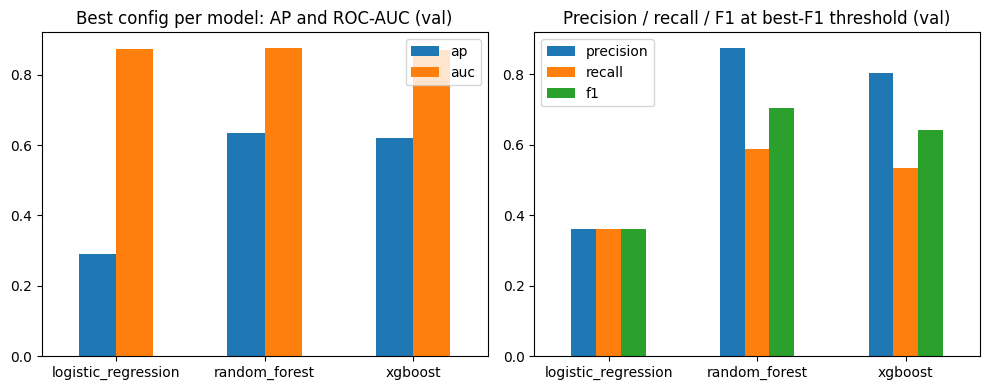

In [16]:
rows = []
for (family, i), d in all_summaries.items():
    rows.append({'family': family, 'run': f'{family}_{i:02d}', 'params': str(d['params']),
                 **{k: d['metrics'][k] for k in METRIC_KEYS}, 'threshold': d['threshold']})
results = pd.DataFrame(rows).sort_values('ap', ascending=False).reset_index(drop=True)

pd.set_option('display.width', 220)
pd.set_option('display.max_colwidth', 70)
print('Validation results, ranked by average precision:')
print(results.drop(columns=['threshold']).round(3).head(15).to_string())

best_per_family = results.loc[results.groupby('family')['ap'].idxmax()].set_index('family')
print('\nBest run per family:')
print(best_per_family.drop(columns=['params', 'threshold']).round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
best_per_family[['ap', 'auc']].plot(kind='bar', ax=axes[0], rot=0)
axes[0].set_title('Best config per model: AP and ROC-AUC (val)')
axes[0].set_xlabel('')
best_per_family[['precision', 'recall', 'f1']].plot(kind='bar', ax=axes[1], rot=0)
axes[1].set_title('Precision / recall / F1 at best-F1 threshold (val)')
axes[1].set_xlabel('')
plt.tight_layout()
plt.show()

## Validation ROC, Precision–Recall, and Confusion Matrices

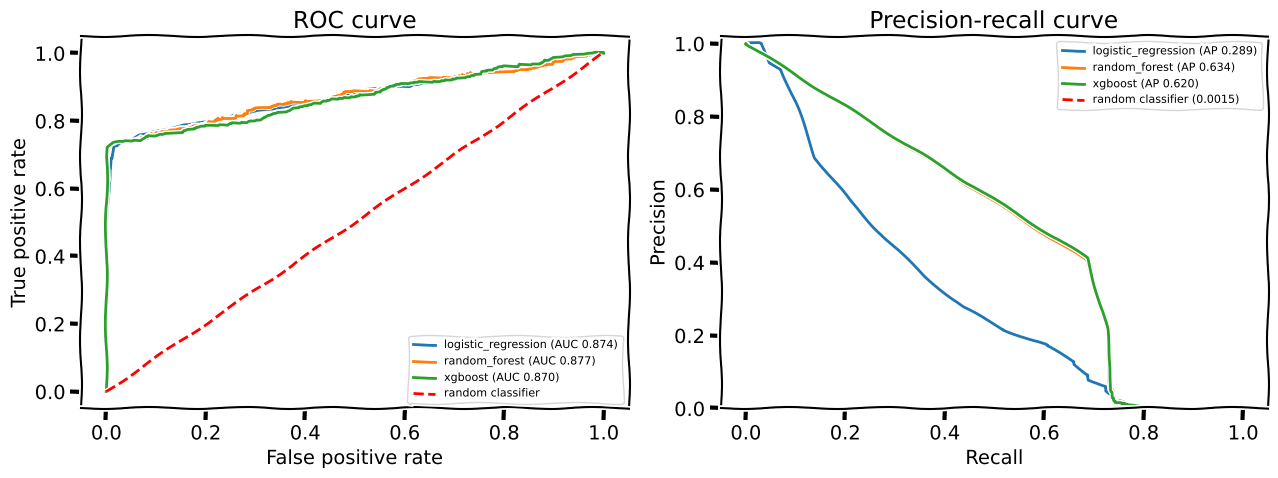

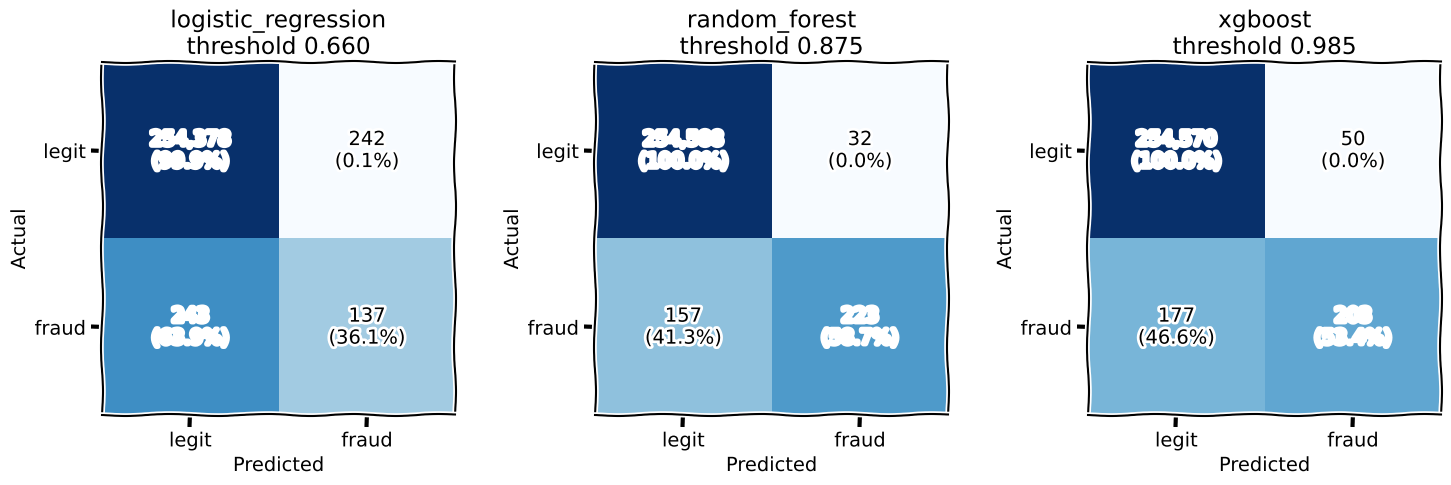

In [17]:
def _style():
    return plt.xkcd() if XKCD_STYLE else plt.rc_context()

def _thin(x, y, n=400):
    keep = np.unique(np.linspace(0, len(x) - 1, min(n, len(x))).astype(int))
    return x[keep], y[keep]

def plot_roc(ax, curves):
    for label, (y_true, s) in curves.items():
        fpr, tpr, _ = roc_curve(y_true, s)
        x, y = _thin(fpr, tpr)
        ax.plot(x, y, label=f'{label} (AUC {roc_auc_score(y_true, s):.3f})')
    ax.plot([0, 1], [0, 1], 'r--', label='random classifier')
    ax.set(xlabel='False positive rate', ylabel='True positive rate', title='ROC curve')
    ax.legend(loc='lower right', fontsize=8)

def plot_pr(ax, curves):
    base = None
    for label, (y_true, s) in curves.items():
        p, r, _ = precision_recall_curve(y_true, s)
        x, y = _thin(r, p)
        ax.plot(x, y, label=f'{label} (AP {average_precision_score(y_true, s):.3f})')
        base = float(np.mean(y_true))
    ax.axhline(base, color='r', linestyle='--', label=f'random classifier ({base:.4f})')
    ax.set(xlabel='Recall', ylabel='Precision', title='Precision-recall curve', ylim=(0, 1.02))
    ax.legend(loc='upper right', fontsize=8)

def plot_cm(ax, y_true, scores, thr, title):
    pred = (scores >= thr).astype(int)
    cm = confusion_matrix(y_true, pred, labels=[0, 1])
    norm = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(norm, cmap='Blues', vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f'{cm[i, j]:,}\n({norm[i, j] * 100:.1f}%)', ha='center', va='center',
                    color='white' if norm[i, j] > 0.5 else 'black')
    ax.set_xticks([0, 1], ['legit', 'fraud'])
    ax.set_yticks([0, 1], ['legit', 'fraud'])
    ax.set(xlabel='Predicted', ylabel='Actual', title=title)

best_keys = {fam: (fam, int(row['run'].rsplit('_', 1)[1])) for fam, row in best_per_family.iterrows()}
val_curves = {fam: (yv, VAL_SCORES[k]) for fam, k in best_keys.items()}

with _style():
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    plot_roc(axes[0], val_curves)
    plot_pr(axes[1], val_curves)
    plt.tight_layout()
    fig.savefig(PLOT_DIR / 'val_roc_pr_best_per_model.png', dpi=150)
    plt.show()

with _style():
    fig, axes = plt.subplots(1, len(best_keys), figsize=(5 * len(best_keys), 4.8))
    for ax, (fam, k) in zip(np.atleast_1d(axes), best_keys.items()):
        plot_cm(ax, yv, VAL_SCORES[k], all_summaries[k]['threshold'],
                f"{fam}\nthreshold {all_summaries[k]['threshold']:.3f}")
    plt.tight_layout()
    fig.savefig(PLOT_DIR / 'val_confusion_matrices.png', dpi=150)
    plt.show()

## Final Evaluation

In [18]:
winner = results.iloc[0]
w_family = winner['family']
w_key = next(k for k, d in all_summaries.items() if k[0] == w_family and str(d['params']) == winner['params'])
w = all_summaries[w_key]
spec = MODELS[w_family]
Xt, yt = TRAIN_SETS[spec['data']]

print(f'Winner: {w_family}  params={w["params"]}  val AP={w["metrics"]["ap"]:.3f}')

model = spec['make'](w['params'], yt)
model.fit(Xt, yt)

scores_eval = get_scores(model, X_eval.values)
final = score_split(y_eval.values, scores_eval, w['threshold'])

with mlflow.start_run(run_name=f'FINAL_EVAL_{w_family}'):
    mlflow.set_tags({'model_family': w_family, 'stage': 'final_eval'})
    mlflow.log_params({**w['params'], 'threshold_from_val': w['threshold']})
    mlflow.log_metrics({f'eval_{k}': v for k, v in final.items()})

print('\nFinal evaluation (eval split, real prevalence) on seen patterns:')
for k, v in final.items():
    print(f'  {k:<22}: {v:.4f}')

Winner: random_forest  params={'max_depth': 10, 'min_samples_leaf': 5, 'n_estimators': 1500}  val AP=0.634

Final evaluation (eval split, real prevalence) on seen patterns:
  ap                    : 0.6395
  auc                   : 0.8667
  recall_at_1pct_fpr    : 0.7232
  precision             : 0.8258
  recall                : 0.5714
  f1                    : 0.6755


## Final Evaluation Plots

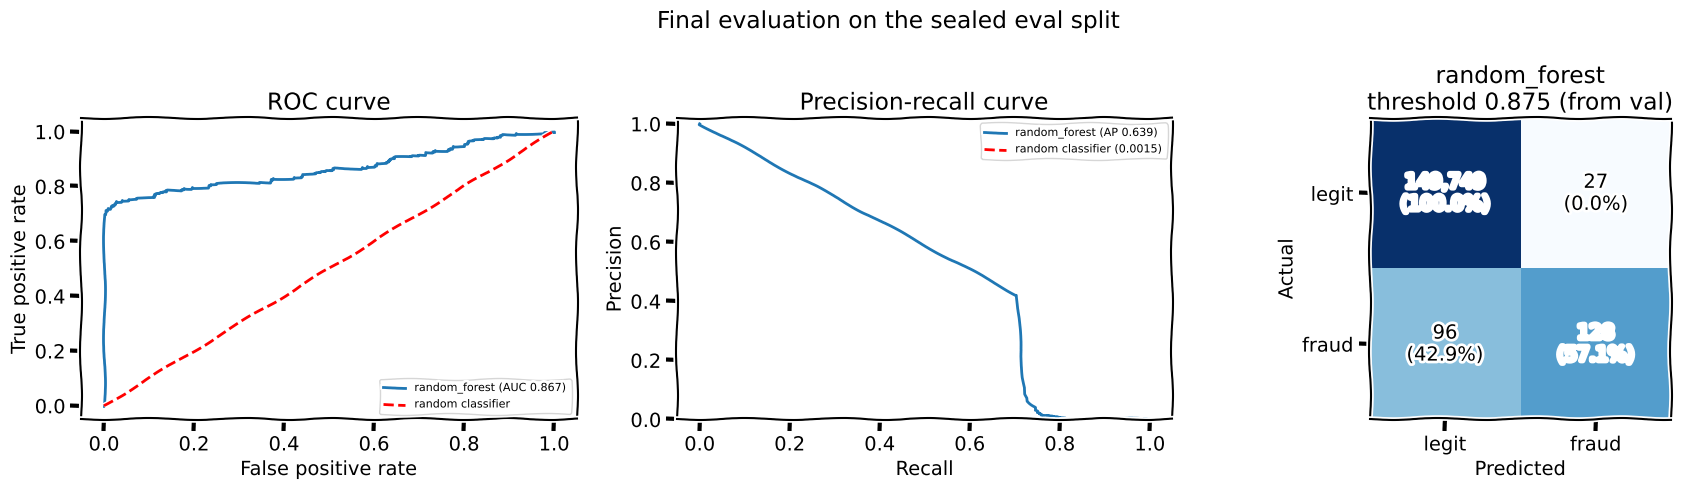

In [19]:
ye = y_eval.values
eval_curves = {w_family: (ye, scores_eval)}

with _style():
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    plot_roc(axes[0], eval_curves)
    plot_pr(axes[1], eval_curves)
    plot_cm(axes[2], ye, scores_eval, w['threshold'],
            f"{w_family}\nthreshold {w['threshold']:.3f} (from val)")
    fig.suptitle('Final evaluation on the sealed eval split')
    plt.tight_layout()
    fig.savefig(PLOT_DIR / 'eval_roc_pr_confusion.png', dpi=150)
    plt.show()

if LOG_PLOTS_TO_MLFLOW:
    with mlflow.start_run(run_name=f'FINAL_EVAL_PLOTS_{w_family}'):
        mlflow.log_figure(fig, 'eval_roc_pr_confusion.png')

## Seen-Pattern and Held-Out-Pattern Comparison

In [20]:
s_val_b = get_scores(model, Xv)
s_eval_b = scores_eval
thr_b = float(np.quantile(s_val_b[yv == 0], 0.99))

train_mask = ~subtype_dev.isin(['account_takeover', 'geo_anomaly']).values
Xh, yh = X_dev.values[train_mask], y_dev.values[train_mask]
fraud_pos = np.where(yh == 1)[0]
legit_pos = np.random.RandomState(GLOBAL_SEED).choice(np.where(yh == 0)[0], 15_000, replace=False)
pos = np.concatenate([fraud_pos, legit_pos])

rf_h = RandomForestClassifier(n_estimators=1500, max_depth=10, min_samples_leaf=5,
                              class_weight='balanced', n_jobs=-1, random_state=GLOBAL_SEED)
rf_h.fit(Xh[pos], yh[pos])
s_val_h = rf_h.predict_proba(X_val.values)[:, 1]
s_eval_h = rf_h.predict_proba(X_eval.values)[:, 1]
thr_h = float(np.quantile(s_val_h[y_val.values == 0], 0.99))

sub_e = subtype_eval.values
print(f'{"type":<22}{"status in held-out":>20}{"baseline AUC":>14}{"heldout AUC":>13}{"baseline rec":>14}{"heldout rec":>13}')
for ft, status in [('card_testing', 'seen'), ('money_laundering_ring', 'seen'),
                   ('account_takeover', 'UNSEEN'), ('geo_anomaly', 'excluded')]:
    m = (sub_e == 'legit') | (sub_e == ft)
    yt = (sub_e[m] != 'legit').astype(int)
    auc_b = roc_auc_score(yt, s_eval_b[m])
    auc_h = roc_auc_score(yt, s_eval_h[m])
    rec_b = (s_eval_b[sub_e == ft] >= thr_b).mean()
    rec_h = (s_eval_h[sub_e == ft] >= thr_h).mean()
    print(f'{ft:<22}{status:>20}{auc_b:>14.3f}{auc_h:>13.3f}{rec_b:>14.3f}{rec_h:>13.3f}')

type                    status in held-out  baseline AUC  heldout AUC  baseline rec  heldout rec
card_testing                          seen         1.000        1.000         0.983        1.000
money_laundering_ring                 seen         1.000        1.000         1.000        1.000
account_takeover                    UNSEEN         0.999        0.990         1.000        0.562
geo_anomaly                       excluded         0.504        0.539         0.000        0.000


## Save Best Model

In [21]:
MODEL_PATH = Path('updated_fraud_model.pkl')

bundle = {
    'model': model,
    'model_family': w_family,
    'params': w['params'],
    'threshold': w['threshold'],
    'scaler': scaler,
    'scale_cols': SCALE_COLS,
    'feature_cols': feature_cols,
    'val_metrics': w['metrics'],
    'eval_metrics': final,
}

joblib.dump(bundle, MODEL_PATH, compress=3)
print(f'Saved {MODEL_PATH} ({MODEL_PATH.stat().st_size / 1e6:.1f} MB)')

loaded = joblib.load(MODEL_PATH)
s_check = get_scores(loaded['model'], X_eval.values)
assert np.allclose(s_check, scores_eval), 'Reloaded model gives different scores!'
print('Reload check passed.')

Saved updated_fraud_model.pkl (8.2 MB)
Reload check passed.


## MLflow UI

Run `mlflow ui --backend-store-uri sqlite:///mlflow.db` from the notebook directory, then open `http://127.0.0.1:5000` to compare recorded runs.